# Mattel Inc. (MAT) - Detaillierte Aktienanalyse

# 1. Einleitung und Zielsetzung

In der Analyse untersuche ich die Finanzdaten von Mattel Inc., einem führenden Spielzeughersteller. Der analysirte Zeitraum liegt zwischen 1993-2025. In der Analyse gehe ich auch darauf ein warum der Kurs so aussieht.

# 2. Import der benötigten Bibliotheken

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt

# 2.2 Datenbeschaffung

Ich lade die Kursdaten von Mattel über Yahoo Finance API:

In [2]:
ticker = yf.Ticker('MAT')
print(ticker.info['longName'])

Mattel, Inc.


In [3]:
mattel = yf.download('MAT', start='1993-01-01', end='2025-01-01')

[*********************100%***********************]  1 of 1 completed


# 2.3 Erste Daten

Hier verschaffe ich mir einen ersten Überblick die verfügbaren Daten in einer Tabelle:

In [4]:
print("Spalten:", mattel.columns)
print("\nErste 10 Zeilen:")
print(mattel.head(10))
print(f"\nAnzahl Datenpunkte: {len(mattel)}")

Spalten: MultiIndex([( 'Close', 'MAT'),
            (  'High', 'MAT'),
            (   'Low', 'MAT'),
            (  'Open', 'MAT'),
            ('Volume', 'MAT')],
           names=['Price', 'Ticker'])

Erste 10 Zeilen:
Price          Close      High       Low      Open   Volume
Ticker           MAT       MAT       MAT       MAT      MAT
Date                                                       
1993-01-04  6.727766  6.858402  6.662448  6.760425   933203
1993-01-05  6.858402  6.858402  6.760425  6.793084  1099023
1993-01-06  6.956382  6.956382  6.891064  6.891064  1697070
1993-01-07  6.825746  6.989041  6.825746  6.956382   509961
1993-01-08  6.695109  6.858404  6.695109  6.825745   453711
1993-01-11  6.564475  6.760429  6.499156  6.727770   631445
1993-01-12  6.695109  6.695109  6.564473  6.564473   544336
1993-01-13  6.760425  6.760425  6.662447  6.662447   482812
1993-01-14  6.695109  6.760427  6.662450  6.727768   663867
1993-01-15  6.662450  6.760428  6.629791  6.695109   782812

Hier überprüfe ich den Zeitraum des Kurses, seinen höchsten und niedrigsten Wert mit `.max()` und `.min()`. Ich benutze `.strftime()` um das Datum in einen lesbaren Text umzuwandeln.

In [5]:
print(f"Zeitraum: {mattel.index[0].strftime('%Y-%m-%d')} bis {mattel.index[-1].strftime('%Y-%m-%d')}")
print(f"Höchster Kurs: ${mattel['High', 'MAT'].max():.2f}") #2f für float und 2 Nachkommastellen
print(f"Niedrihster Kurs: ${mattel['Low','MAT'].min():.2f}")

Zeitraum: 1993-01-04 bis 2024-12-31
Höchster Kurs: $39.49
Niedrihster Kurs: $4.94


# 2.4 Überblick: 30 Jahre Mattel-Aktienentwicklung

Der erste Plot gibt ein Gesamtbild der Aktienentwicklung über den kompletten Analysezeitraum von 1993 bis 2025. Dies ermöglicht es, langfristige Trends, bedeutende Kursausschläge und verschiedene Marktphasen zu identifizieren.

Besonders interessant ist wie stark sich bestimmte Produkte auf die Aktien ausgewirkt haben. Zum Beispiel kam die erste Generation Monster High Puppen, Filme und samt Serie dazu 2010 raus, wie zu sehen ist hatte dies einen großen Einfluss auf die Aktie.

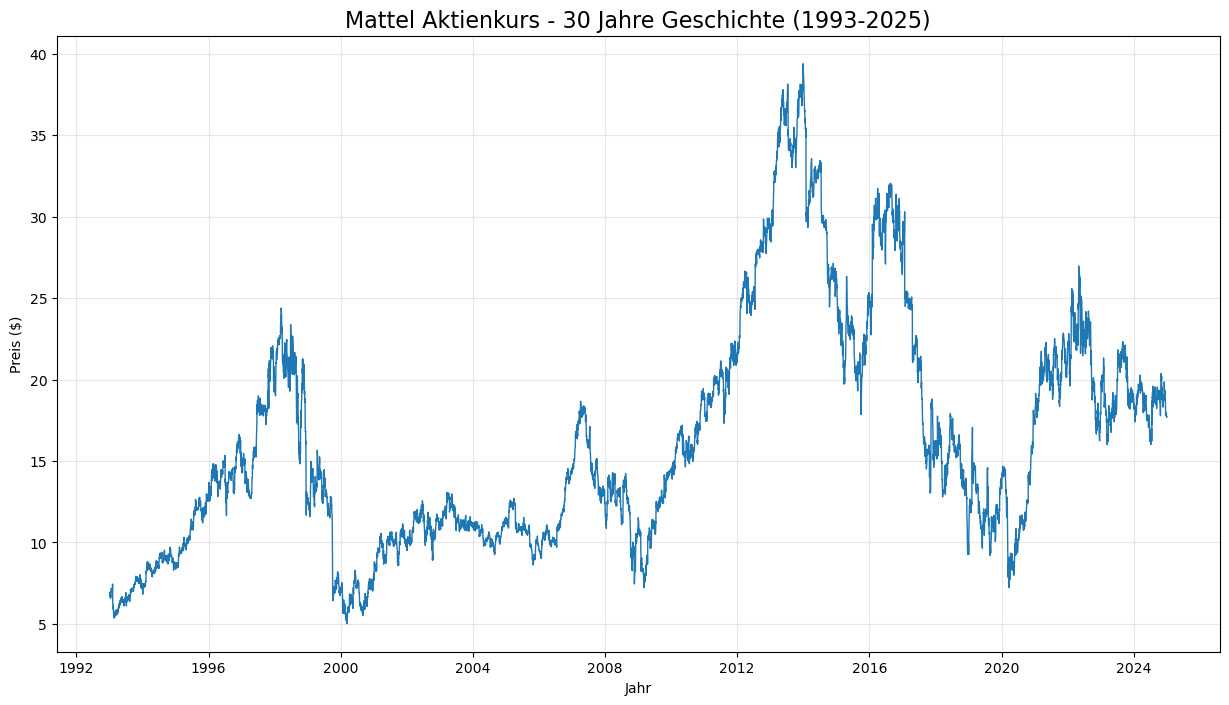

In [6]:
plt.figure(figsize=(15,8))
plt.plot(mattel.index, mattel['Close', 'MAT'], linewidth=1)
plt.title('Mattel Aktienkurs - 30 Jahre Geschichte (1993-2025)', fontsize=16)
plt.xlabel('Jahr')
plt.ylabel('Preis ($)')
plt.grid(True, alpha=0.3)
plt.show()

# 2.4.1 Volatilität, Renditen und Moving Averages 

In diesem Schritt berechne ich die rollende **Volatilität** von Mattel über ein 1-Jahres-Fenster. Dafür verwende ich `pct_change()` um die täglichen Renditen zu ermitteln und `rolling(252).std()` um die Standardabweichung über 252 Handelstage zu berechnen.

Text(0, 0.5, 'Volatilität')

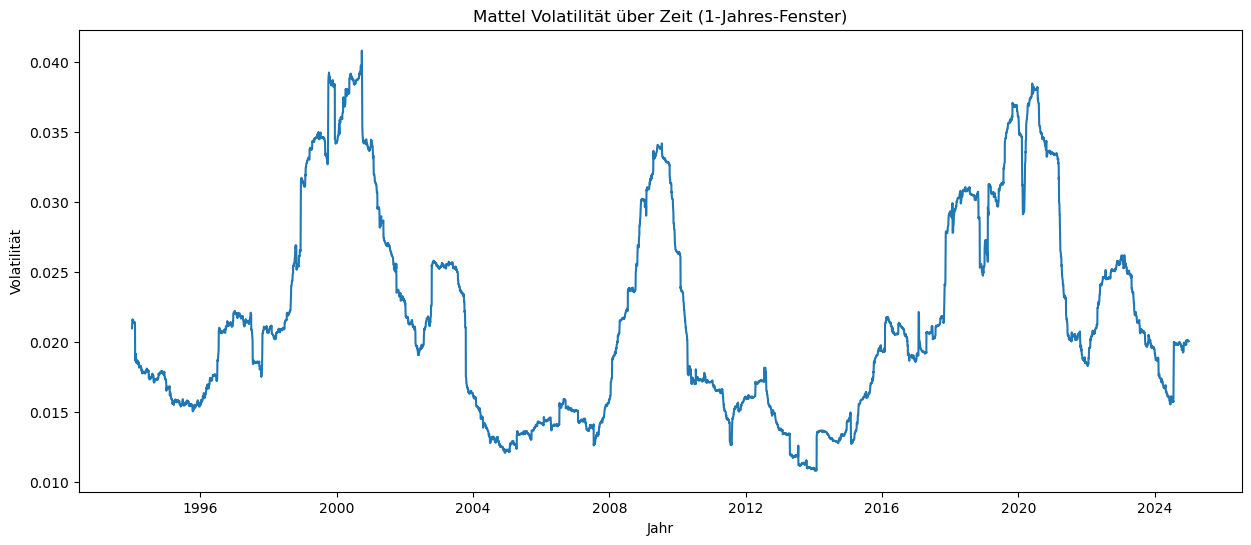

In [7]:
rolling_vol = mattel['Close', 'MAT'].pct_change().rolling(window=252).std() # 252 Handelstage pro Jahr

plt.figure(figsize=(15,6))
plt.plot(rolling_vol.index, rolling_vol)
plt.title('Mattel Volatilität über Zeit (1-Jahres-Fenster)')
plt.xlabel('Jahr')
plt.ylabel('Volatilität')

Die tägliche Volatilität von Mattel bewegt sich bei ungefähr 2,27%. Dies bedeutet, dass Mattel eine mittlere Volatilität hat - die Aktie ist also nicht spezifisch riskant, aber auch nicht besonders stabil.

Die höchsten Werte sind in 2000, 2008 und rund um 2020 zu messen. Im Jahr 2000 lag die Aktie bei 4% Volatilität - diese Zeit muss sehr riskant gewesen sein. Auch 2008 und 2020 war sie sehr hoch mit über 3,5%.

Eine Investitionsentscheidung in Mattel muss jeder selbst treffen, jedoch zeigt die Volatilitätsanalyse deutlich, dass Mattel alle paar Jahre erhebliche Schwankungen aufweist, ob nun wegen internen oder externen Problemen.

Für die **Tagesrenditen** erstelle ich ein Histogramm. In diesem kann nach % verglichen werden, wie stark die Aktie schwankt. Es sind die Wahrscheinlichkeiten von Gewinnen/Verlusten.

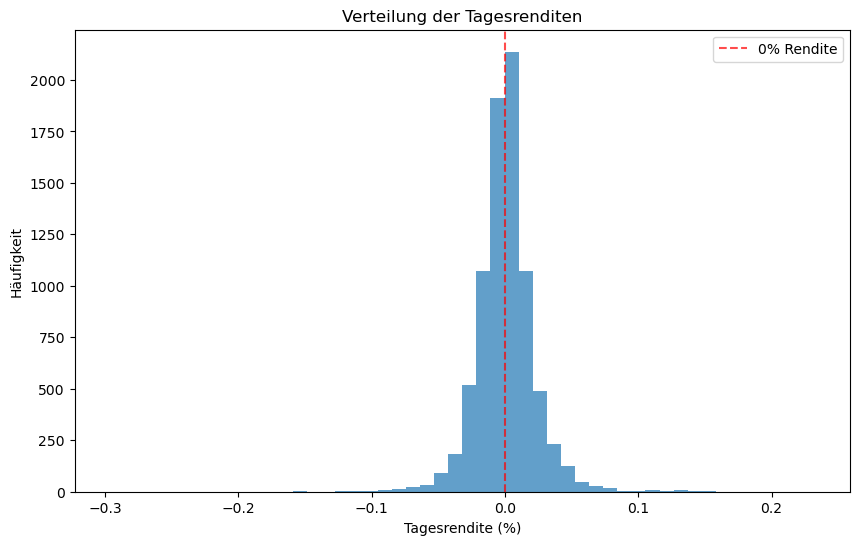

In [80]:
daily_returns = mattel['Close', 'MAT'].pct_change()
plt.figure(figsize=(10, 6))
plt.hist(daily_returns.dropna(), bins=50, alpha=0.7)
plt.xlabel('Tagesrendite (%)')
plt.ylabel('Häufigkeit')
plt.title('Verteilung der Tagesrenditen')
plt.axvline(0, color='red', linestyle='--', alpha=0.7, label='0% Rendite')
plt.legend()
plt.show()

Die Tagesrenditen zeigen, dass Mattel normale Aktien-Eigenschaften hat. Die meisten Tage sind bei 0%, was bedeutet, dass die Aktie an vielen Tagen kaum schwankt.

Die Verteilung ist annähernd normalverteilt und symmetrisch um 0%. Die meisten Bewegungen liegen zwischen -10% und +10%, mit nur sehr wenigen extremen Tagen außerhalb dieses Bereichs. 

Ich erstelle ein **Moving Average Diagramm** mit dem Mattel Kurs, einem 30-Tage Durchschnitt und einem 90-Tage Durchschnitt, um **Trends zu erkennen**.

Text(0.5, 1.0, 'Mattel: Kurs vs. Trends')

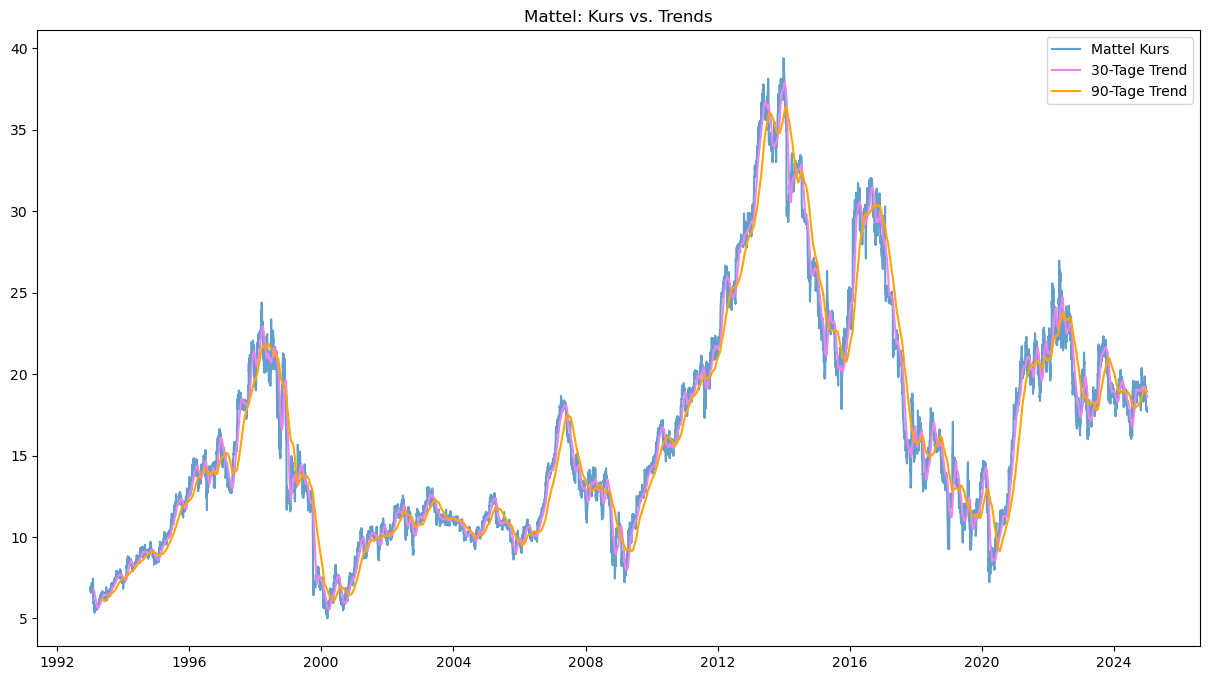

In [9]:
ma_30 = mattel['Close', 'MAT'].rolling(30).mean()
ma_90 = mattel['Close', 'MAT'].rolling(90).mean()

plt.figure(figsize=(15, 8))
plt.plot(mattel.index, mattel['Close', 'MAT'], label='Mattel Kurs', alpha=0.7)
plt.plot(mattel.index, ma_30, label='30-Tage Trend', color='violet')
plt.plot(mattel.index, ma_90, label='90-Tage Trend', color='orange')
plt.legend()
plt.title('Mattel: Kurs vs. Trends')

Der 30-Tage Durchschnitt zeigt, dass er nur minimal vom generellen Mattel Kurs abweicht. Der 90-Tage Durchschnitt weicht dagegen deutlich häufiger ab.

Der 30-Tage Trend ist schneller und zeigt mehr Details, während der 90-Tage Trend langsamer und glatter verläuft. Er zeigt vor allem große Trends auf.

# 3. Analyse spezifischer Marktphasen

# 3.1 Monster High Boom

Für meine erste Analyse einer Marktphase sowie für die daruffolgenden erstelle ich eine Tabelle mit den ersten Daten sowie des Beginnnwerts, Endwerts und Höchstwerts der Phase. Darauf folgt ein Graph zur Visualisierung.

Jeder Abschnitt hat seine eigenen Erklärungen warum, der Kurs gestiegen sowie gefallen sein könnte.

In [10]:
close_prices = mattel['Close', 'MAT']
boom_period = close_prices['2010':'2016']

print("Boom Period Shape:", boom_period.shape)
print("Frist few values:", boom_period.head())

start_preis = boom_period.iloc[0]
end_preis = boom_period.iloc[-1]
max_preis = boom_period.max()

print(f"Monster High Boom (2010-2016):")
print(f"Start: ${start_preis:.2f}")
print(f"Peak: ${max_preis:.2f}")
print(f"Ende: ${end_preis:.2f}")

Boom Period Shape: (1762,)
Frist few values: Date
2010-01-04    14.349030
2010-01-05    14.054727
2010-01-06    13.997303
2010-01-07    14.356206
2010-01-08    14.191112
Name: (Close, MAT), dtype: float64
Monster High Boom (2010-2016):
Start: $14.35
Peak: $39.40
Ende: $26.45


Hier ist der Monster High Boom, erwähnt in Kapitel 2.4, nochmals genauer zu sehen. Wie deutlich erkennbar ist, stieg die Aktie von 14.35 USD (2010) auf 39.40 USD (2015) - eine Steigerung um 175%. 2015-2016 stürzte die Aktie schließlich ab, als die 2. Generation der Monster High Puppen auf den Markt kam. Diese wurden von der Zielgruppe teilweise abgelehnt, da das neue Design vom beliebten Original abwich.

# 3.1.1 Monster High Boom Graph

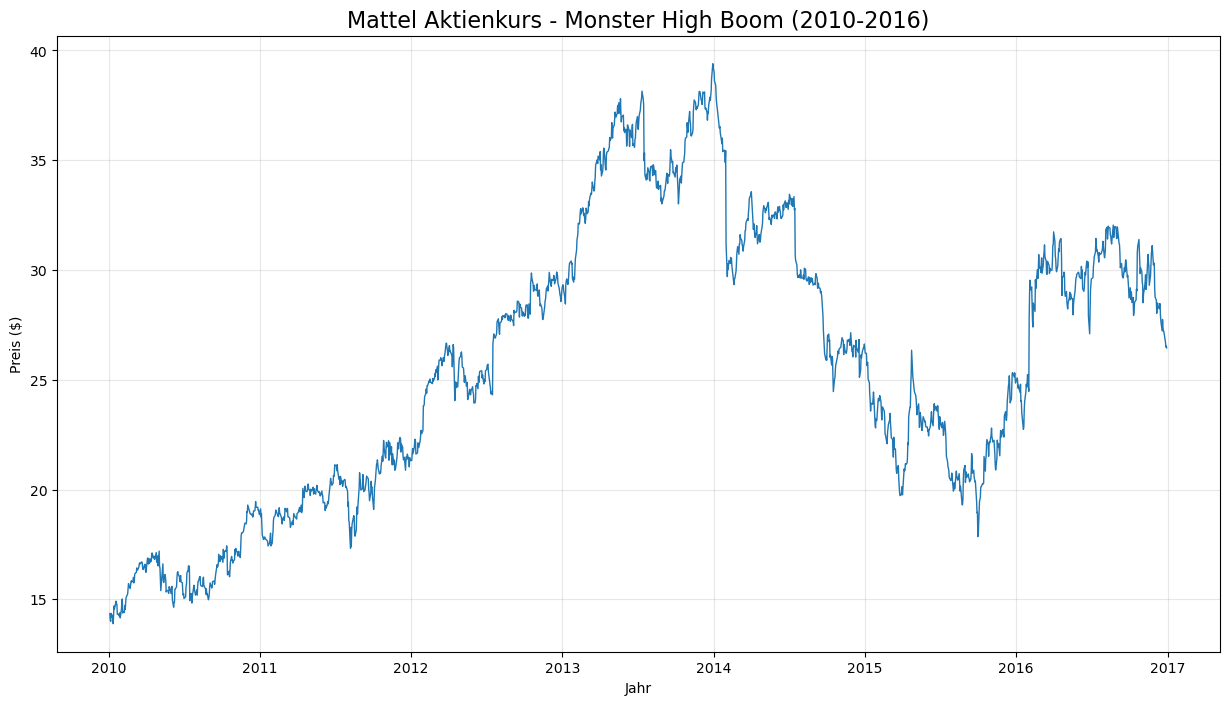

In [58]:
plt.figure(figsize=(15,8))
plt.plot(boom_period.index, boom_period, linewidth=1)
plt.title('Mattel Aktienkurs - Monster High Boom (2010-2016)', fontsize=16)
plt.xlabel('Jahr')
plt.ylabel('Preis ($)')
plt.grid(True, alpha=0.3)
plt.show()

Der Graph bestätigt die Daten eindrucksvoll. Besonders zwischen 2012-2014 wurden zahlreiche Monster High Filme veröffentlicht, 2015 folgte der letzte Film der 1. Generation. 

Der Crash 2015-2016 lässt sich durch zwei Faktoren erklären: Zum einen kamen die redesignten Puppen bei der Zielgruppe nicht an, zum anderen war die ursprüngliche Fanbase inzwischen älter geworden und aus dem Zielsegment herausgewachsen.

# 3.1.2 Weitere wichtige Events zwischen 2010 und 2016.

Parallel zum Monster High Erfolg verfolgte Mattel weitere strategische Initiativen. 2011 übernahm das Unternehmen Hit Entertainment, den Produzenten beliebter Kinderserien wie Thomas & Friends. Hot Wheels stellte zudem einen Weltrekord für die längste Ramp-zu-Ramp-Sprungdistanz auf.

2012 startete die Mattel Children's Foundation eine besondere Initiative: In Zusammenarbeit mit Barbie wurden "Ella, Friend of Barbie"-Puppen entwickelt und an Organisationen gespendet, die mit krebskranken Kindern und anderen Kindern mit medizinisch bedingtem Haarausfall arbeiten.

Die Expansionsstrategie setzte sich fort mit der Übernahme von MEGA Brands (2014) und der Einführung neuer Barbie-Körpertypen (2016), die für mehr Diversität und Körperpositivität sorgten.

# 3.1.3 Jährliche Rendite der Jahre 2010-2016

In diesem Abschnitt wird ein Balkendiagramm zur Analyse der jährlichen Renditen während der Monster High Periode (2010-2016) dargestellt. Das Diagramm wurde mit `plt.bar()` erstellt und zeigt die prozentuale Performance für jedes Jahr.

Text(0, 0.5, 'Rendite (%)')

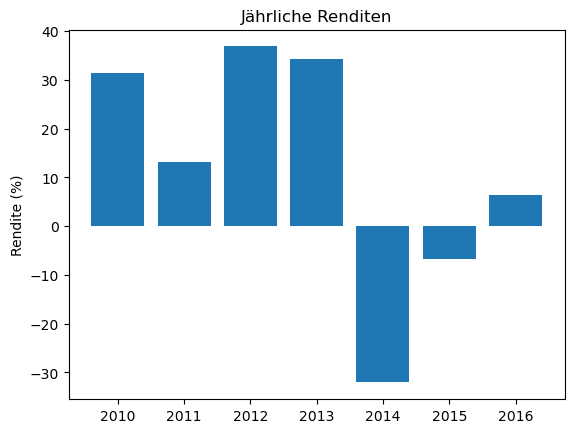

In [89]:
annual_returns = mattel['Close', 'MAT'].resample('YE').last().pct_change()
annual_MH = annual_returns['2010':'2016']
plt.bar(annual_MH.index.year, annual_MH * 100)
plt.title('Jährliche Renditen')
plt.ylabel('Rendite (%)')

Interessant ist zu sehen, dass die Rendite 4 Jahre hintereinander positiv war. 2010 stieg die Rendite um etwa 32%, 2011 um weitere 13%, 2012 um fast 37% und 2013 um etwa 34%. Erst 2014 sank sie um etwa -32% und im darauffolgenden Jahr nochmals um -5%. Erst 2016 stieg die Rendite wieder leicht um 7%.

# 3.2 Mattels Geschichte 1993-2000

In [12]:
close_prices = mattel['Close', 'MAT']
mattel_history = close_prices['1993':'2000']

print("History Shape:", mattel_history.shape)
print("Frist few values:", mattel_history.head())

start_preis = mattel_history.iloc[0]
end_preis = mattel_history.iloc[-1]
max_preis = mattel_history.max()

print(f"Mattel Geschichte (1993-2000):")
print(f"Start: ${start_preis:.2f}")
print(f"Peak: ${max_preis:.2f}")
print(f"Ende: ${end_preis:.2f}")

History Shape: (2020,)
Frist few values: Date
1993-01-04    6.727766
1993-01-05    6.858402
1993-01-06    6.956382
1993-01-07    6.825746
1993-01-08    6.695109
Name: (Close, MAT), dtype: float64
Mattel Geschichte (1993-2000):
Start: $6.73
Peak: $24.40
Ende: $8.11


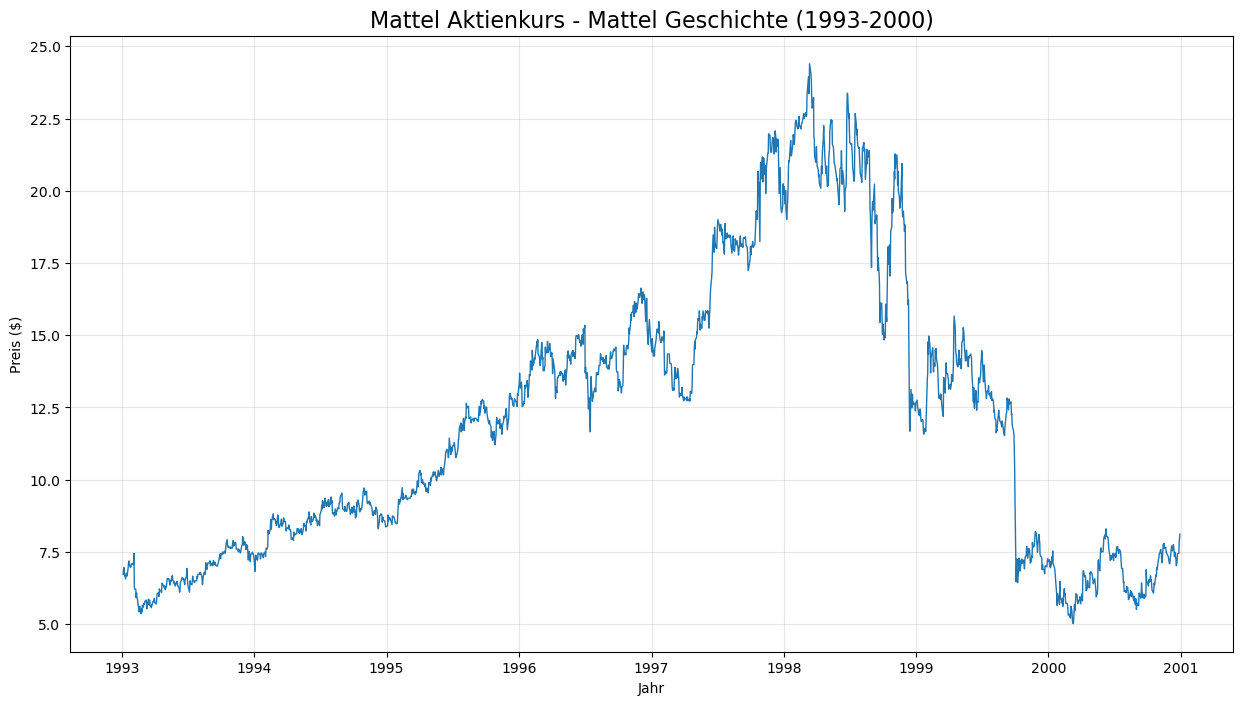

In [13]:
mattel_history = close_prices['1993':'2000']
plt.figure(figsize=(15,8))
plt.plot(mattel_history.index, mattel_history, linewidth=1)
plt.title('Mattel Aktienkurs - Mattel Geschichte (1993-2000)', fontsize=16)
plt.xlabel('Jahr')
plt.ylabel('Preis ($)')
plt.grid(True, alpha=0.3)
plt.show()

Wie deutlich erkennbar ist, stieg die Aktie von 6.73 USD (1993) auf 24.40 USD (2000) - eine Steigerung um 262.6%. In nur einem einzigen Jahr sank diese jedoch wieder von 24.40 USD auf 8.11 USD, das entspricht einem Verlust von -66.8%. Diese Entwicklung lässt sich erklären.

Mattel verzeichnete über die Jahre bis 1998 mehrere bedeutende Meilensteine. 1993 wurde Fisher-Price übernommen, ein etablierter Hersteller für Babyspielzeug. 1997 folgte eine strategische Zusammenarbeit zwischen Hot Wheels und NASCAR, bei der zwei Rennfahrlegenden (Kyle Petty und Jack Baldwin) beteiligt waren. 

Das Jahr 1998 wurde zum Wendepunkt mit drei außergewöhnlichen Ereignissen: Mattel übernahm American Girl im selben Jahr, in dem der erste Store in Chicago eröffnet wurde. Parallel dazu arbeiteten sie mit UCLA Health zusammen und wurden Namensgeber des UCLA Mattel Children's Hospital. Schließlich wurde Barbie in die National Toy Hall of Fame aufgenommen - eine ultimative Anerkennung der Marke.

Wie jedoch zu sehen ist, fiel die Aktie plötzlich sehr stark zwischen 1999 und Ende 2000. Der Grund dafür kann spekuliert werden. Zunächst ist anzumerken, dass Mattel 2000 zum Hauptlizenznehmer der Harry Potter Spielzeugserie wurde. Was sich anhört wie etwas Positives, erwies sich jedoch als problematisch: Der erste Harry Potter Film kam erst 2001 heraus und damit der eigentliche Hype. Zusätzlich erhielt Mattel lediglich die Lizenz für Spielwaren und für keine anderen Produktkategorien.

Zusätzlich platzte im März 2000 die Dotcom-Blase in den USA, die alle Aktienkurse einbrechen ließ. Die weit verbreitete Spekulation, dass Internet automatisch Profit bedeute, hatte zur Folge, dass Firmen ohne nennenswerte Umsätze Milliarden wert waren. Dieser Crash betraf nicht nur Tech-Aktien, sondern alle Bereiche, da Investoren in Panik gerieten und ihre gesamten Portfolios verkauften.

# 3.2.1 Handelsvolumen 1993-2000

In diesem Schritt analysiere ich das Handelsvolumen, welches die Aktivität und Nervosität der Investoren widerspiegelt. Für die Darstellung verwende ich einen Stem Plot mit `plt.stem()`, da dieser Chart-Typ die Volumen-Spikes deutlicher visualisiert als ein herkömmlicher Linienplot.

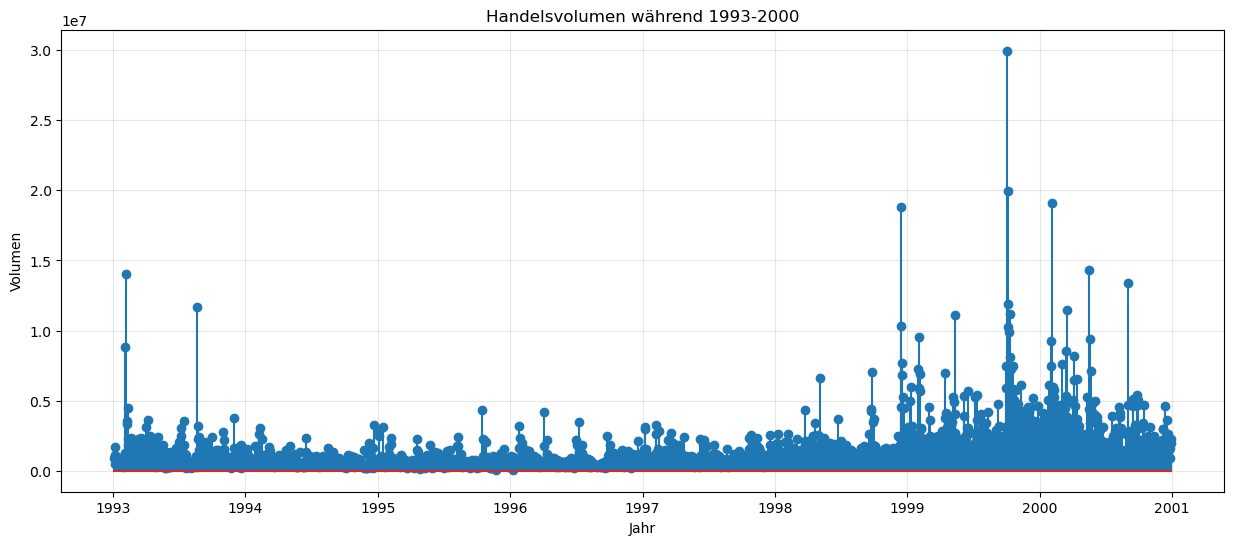

In [14]:
volume_data = mattel['Volume', 'MAT']
volume_history = volume_data['1993':'2000']

plt.figure(figsize=(15, 6))
plt.stem(volume_history.index, volume_history)
plt.title('Handelsvolumen während 1993-2000')
plt.xlabel('Jahr')
plt.ylabel('Volumen')
plt.grid(True, alpha=0.3)
plt.show()

Der Stem Plot zeigt sehr deutlich, dass 1993 viel gehandelt wurde - bis zu fast 15 Millionen Aktien. Danach herrschte sehr lange Ruhe und es gab keine hohen Spikes bis 1999. Ab 1999 stieg das Handelsvolumen auf fast 20 Millionen Aktien und erreichte kurz vor 2000 seinen Höhepunkt mit etwa 30 Millionen gehandelten Aktien pro Tag. Als die Dotcom-Blase platzte, gerieten die Investoren in Panik und verkauften ihre Aktien schnell. Dies zog sich eine Weile hin, bis sich das Volumen 2001 wieder beruhigte.

# 3.2.2 Negative und Positive Handelstage

Hier erstelle ich ein Kreisdiagramm.

Das Kreisdiagramm visualisiert die Verteilung positiver und negativer Handelstage. Als Entscheidungsgrundlage dienen die täglichen Renditen, die mittels `pct_change()` berechnet werden und anzeigen, ob der Schlusskurs im Vergleich zum Vortag gestiegen oder gefallen ist.


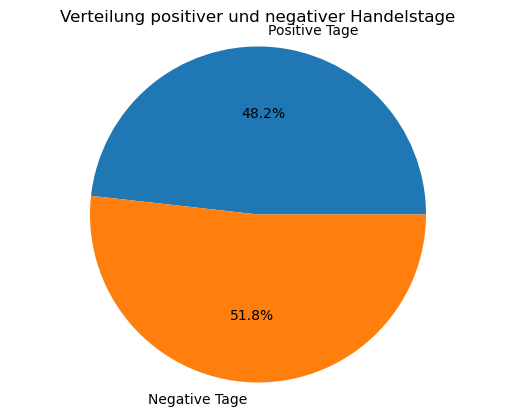

In [86]:
returns = mattel['Close', 'MAT'].pct_change()
returns_90s = returns['1993':'2000']

positive = (returns_90s > 0).sum()
negative = (returns_90s < 0).sum()

categories = ['Positive Tage', 'Negative Tage']
quantities = [positive, negative]

fig, ax = plt.subplots()
plt.pie(quantities, labels=categories, autopct='%1.1f%%')
ax.axis('equal')
plt.title('Verteilung positiver und negativer Handelstage')
plt.show()

Insgesamt ist zu erkennen, dass sich die Anzahl positiver und negativer Handelstage nahezu gleichmäßig verteilt, wobei negative Handelstage mit einem Anteil von 51,8 % leicht überwiegen. Dies deutet darauf hin, dass die Aktie von Mattel trotz der zuvor beobachteten starken Kursschwankungen im betrachteten Zeitraum insgesamt relativ ausgeglichen war.

# 3.3 Rückrufe und Strafen 2001-2009

In [96]:
close_prices = mattel['Close', 'MAT']
crisis_period = close_prices['2001':'2009']

print("Crisis Period Shape:", crisis_period.shape)
print("Frist few values:", crisis_period.head())

start_preis = crisis_period.iloc[0]
end_preis = crisis_period.iloc[-1]
max_preis = crisis_period.max()

print(f"Rückrufe und Strafen (2001-2009):")
print(f"Start: ${start_preis:.2f}")
print(f"Peak: ${max_preis:.2f}")
print(f"Ende: ${end_preis:.2f}")

Crisis Period Shape: (2263,)
Frist few values: Date
2001-01-02    7.693585
2001-01-03    8.109152
2001-01-04    8.704419
2001-01-05    8.704419
2001-01-08    8.811120
Name: (Close, MAT), dtype: float64
Rückrufe und Strafen (2001-2009):
Start: $7.69
Peak: $18.66
Ende: $14.34


Zwischen 2001 und 2009 durchlebte Mattel eine schwierige Phase mit internen und externen Herausforderungen. Der Chart zeigt, dass die Aktie lange seitwärts bewegte bis 2007. Ende 2009 hatte sich der Aktienwert im Vergleich zu 2001 dennoch fast verdoppelt. Insgesamt steigt die Aktie 142,65% aber stürzt darauf wieder 23,15%.

Anfang 2001 bis 2002 waren viele Aktien noch von der Dotcom-Blase betroffen. Trotzdem enthüllte Mattel 2001 das erste lebensgroße Hot Wheels Auto und brachten ihren ersten Barbie Film auf den Markt und darauf viele mehr. Zwei Jahre später veröffentlichten sie den ersten American Girl Film für das Fernsehen.

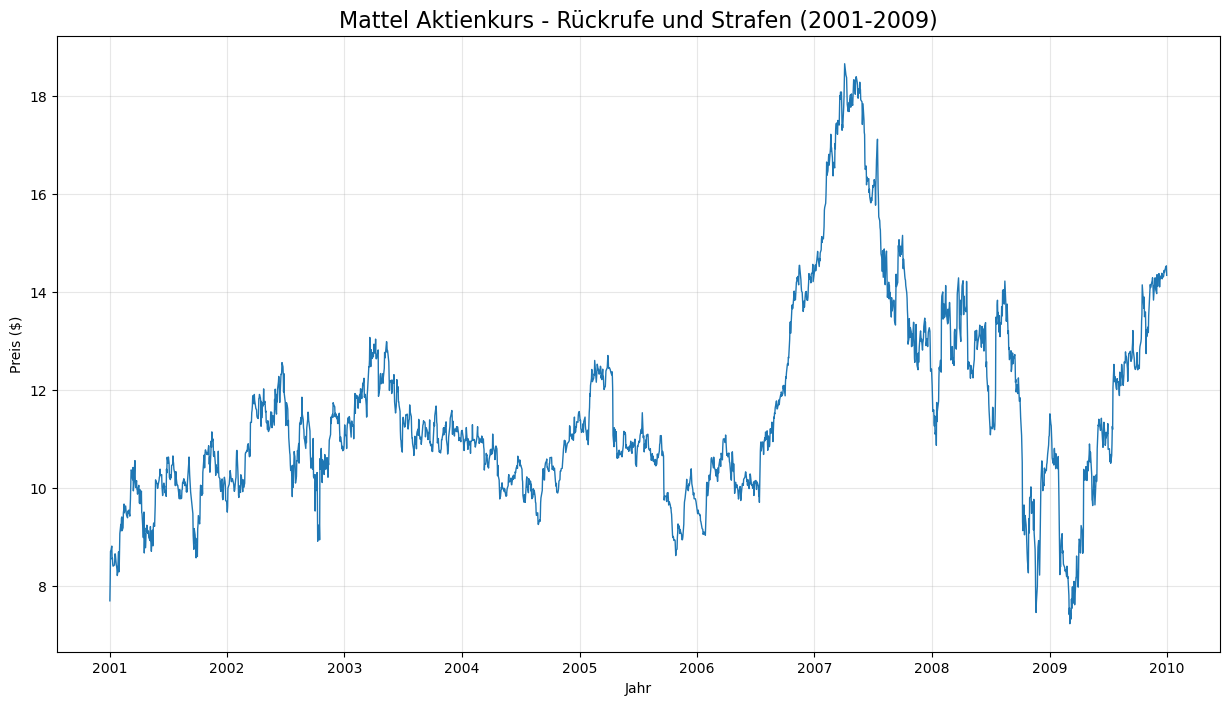

In [67]:
crisis_period = close_prices['2001':'2009']
plt.figure(figsize=(15,8))
plt.plot(crisis_period.index, crisis_period, linewidth=1)
plt.title('Mattel Aktienkurs - Rückrufe und Strafen (2001-2009)', fontsize=16)
plt.xlabel('Jahr')
plt.ylabel('Preis ($)')
plt.grid(True, alpha=0.3)
plt.show()

Ab 2007, als sich die Aktienkurse erholten, wurde Mattel von einer Reihe schwerwiegender Skandale erschüttert:

**2007 - Doppelte Rückruf-Krise:**
Zunächst mussten 1,5 Millionen Spielzeuge wegen bleihaltiger Farbe zurückgerufen werden, was einen Schaden von 30 Millionen USD verursachte. Nur zwei Wochen später folgte der größte Rückruf der Firmengeschichte: 18 Millionen Spielzeuge mit gefährlichen Magneten mussten vom Markt genommen werden.

**2008-2009 - Finanzkrise und weitere Probleme:**
Die globale Finanzkrise 2008 verstärkte den bereits durch die Skandale angeschlagenen Aktienkurs zusätzlich. 2009 verhängte die amerikanische Verbraucherschutzkommission eine Strafe von 2,3 Millionen USD gegen Mattel und Fisher-Price, da sie wissentlich bleihaltige Spielzeuge vermarktet hatten.

**2010 - Fortsetzung der Probleme:**
Selbst 2010 war die Krise nicht vorbei: Weitere 11 Millionen Artikel mussten zurückgerufen werden.

Parallel zu diesen Krisen setzte Mattel weiterhin auf ihre Kernmarke Barbie und brachte verschiedene neue Varianten und Filme auf den Markt.

# 3.3.1 Volatilität 2001-2009

In diesem Schritt berechne ich die rollende **Volatilität** von Mattel zwischen 2001-2009. Dafür verwende ich `pct_change()` um die täglichen Renditen zu ermitteln und `rolling(252).std()` um die Standardabweichung über 252 Handelstage zu berechnen.

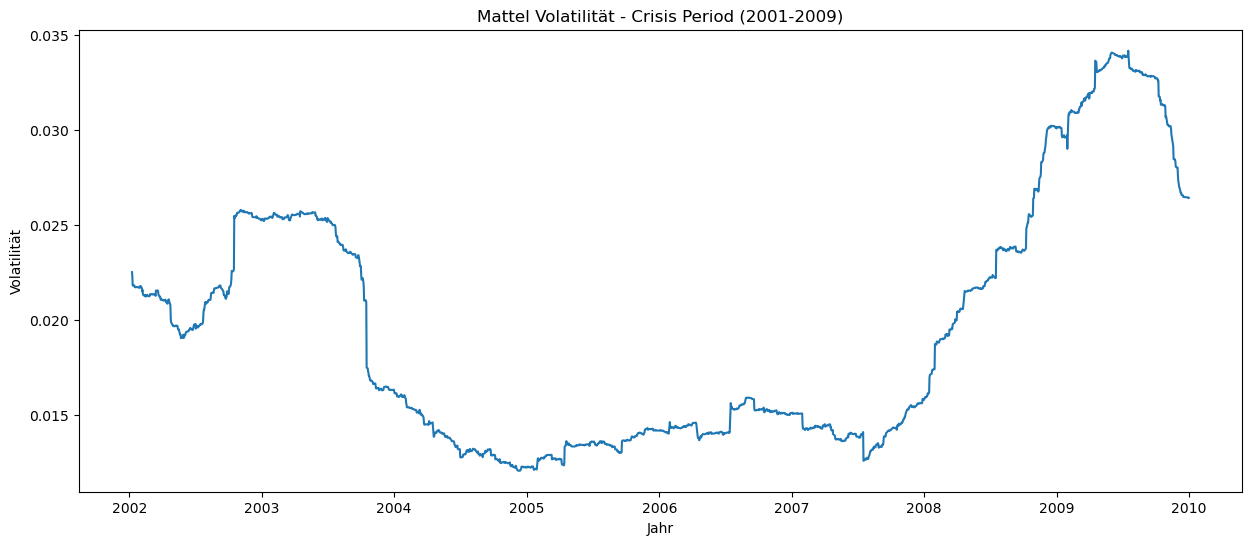

In [63]:
rolling_vol_2 = crisis_period.pct_change().rolling(window=252).std()

plt.figure(figsize=(15,6))
plt.plot(rolling_vol_2.index, rolling_vol_2)  # <- Hier der Fix!
plt.title('Mattel Volatilität - Crisis Period (2001-2009)')
plt.xlabel('Jahr')
plt.ylabel('Volatilität')
plt.show()

Mit der rollenden Volatilität von 2001-2009 sind die unterschiedlichen Risikophasen sehr gut zu erkennen. Von 2005 bis 2008 zeigt sich die niedrigste Volatilität bei ungefähr 1,3%, was die Aktie in dieser Zeit sehr stabil machte.

In den Jahren 2001-2004 sind noch die Nachwirkungen der Dotcom-Blase erkennbar, jedoch liegt die Volatilität bereits niedriger bei etwa 2,5%. Erst während und nach den Skandalen sowie der Finanzkrise erreicht die Volatilität ihren höchsten Wert von ungefähr 3,5%.

Die niedrige Volatilität von 2005-2008 (1,3%) hätte Mattel für risikoscheue Investoren attraktiv gemacht. Die Aktie erschien stabil und kalkulierbar. Jedoch zeigt diese Analyse auch die Unvorhersagbarkeit - niemand konnte die Skandale oder die Finanzkrise antizipieren. 

# 3.3.2 Positive und Negative Jahre 2001-2009

In diesem Abschnitt wird die jährliche Rendite zwischen 2001 und 2009 analysiert. Dafür wurde ein Balkendiagramm mit `plt.bar()` erstellt, das die Rendite für jedes einzelne Jahr darstellt. Daraufhin folgt ein Kreisdiagramm zur Visualisierung, ob die Aktie während dieser Zeit mehr positive oder negative Handelstage aufwies.

Text(0, 0.5, 'Rendite (%)')

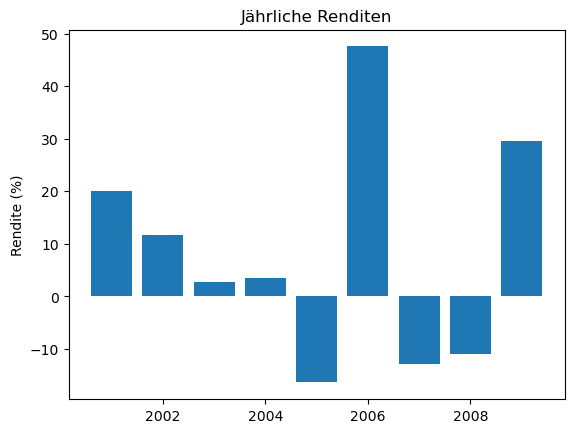

In [84]:
annual_returns = mattel['Close', 'MAT'].resample('YE').last().pct_change()
annual_data = annual_returns['2001':'2009']
plt.bar(annual_data.index.year, annual_data * 100)
plt.title('Jährliche Renditen')
plt.ylabel('Rendite (%)')

Interessant ist zu sehen, dass 2006 das beste Jahr war mit fast 50% Anstieg. Dann fiel 2007 mit den ersten Skandalen die Rendite um 12% und 2008 mit der Finanzkrise nochmals ähnlich stark. Erst 2009 stieg die Rendite wieder um 30%. Der größte Verlust war 2005 mit etwa 15% Rückgang.

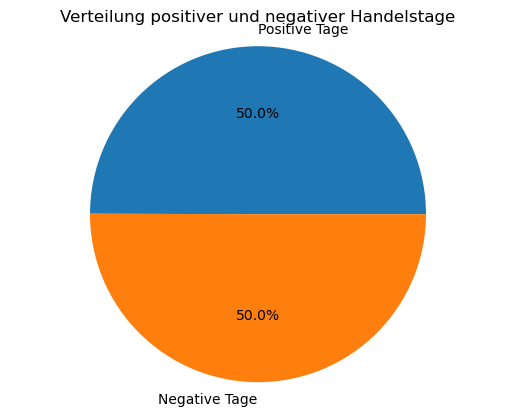

In [87]:
returns = mattel['Close', 'MAT'].pct_change()
returns_00s = returns['2001':'2009']

positive = (returns_00s > 0).sum()
negative = (returns_00s < 0).sum()

categories = ['Positive Tage', 'Negative Tage']
quantities = [positive, negative]

fig, ax = plt.subplots()
plt.pie(quantities, labels=categories, autopct='%1.1f%%')
ax.axis('equal')
plt.title('Verteilung positiver und negativer Handelstage')
plt.show()

Besonders interessant zu sehen ist in diesem Kreisdiagramm, dass sich die Schwankungen perfekt ausgleichen. Insgesamt war diese Periode mit positiven und negativen Tagen exakt 50/50 aufgeteilt.

# 3.4 Jubiläen und Meilensteine 2017-2024

In [97]:
close_prices = mattel['Close', 'MAT']
covid_period = close_prices['2017':'2024']

print("Covid Period Shape:", covid_period.shape)
print("Frist few values:", covid_period.head())

start_preis = covid_period.iloc[0]
end_preis = covid_period.iloc[-1]
max_preis = covid_period.max()

print(f"Jubiläen und Meilensteine (2017-2024):")
print(f"Start: ${start_preis:.2f}")
print(f"Peak: ${max_preis:.2f}")
print(f"Ende: ${end_preis:.2f}")

Covid Period Shape: (2012,)
Frist few values: Date
2017-01-03    27.345446
2017-01-04    28.094374
2017-01-05    29.707449
2017-01-06    29.256172
2017-01-09    29.304180
Name: (Close, MAT), dtype: float64
Jubiläen und Meilensteine (2017-2024):
Start: $27.35
Peak: $30.30
Ende: $17.73


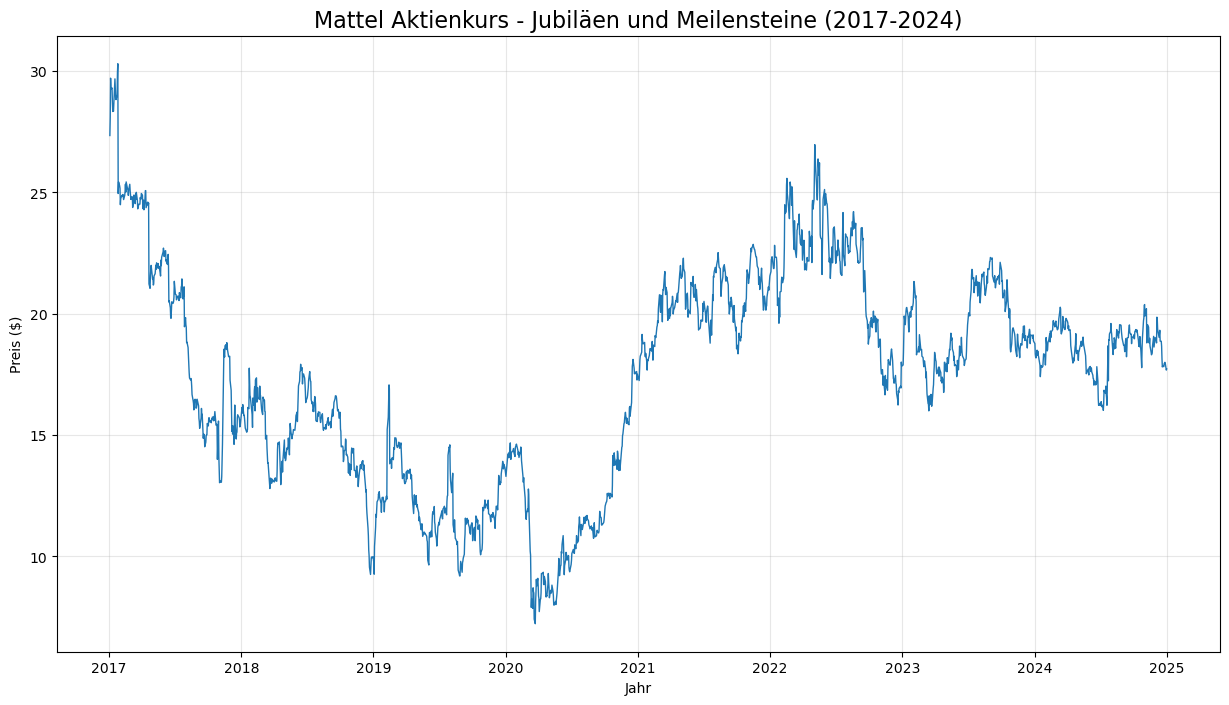

In [95]:
covid_period = close_prices['2017':'2024']
plt.figure(figsize=(15,8))
plt.plot(covid_period.index, covid_period, linewidth=1)
plt.title('Mattel Aktienkurs - Jubiläen und Meilensteine (2017-2024)', fontsize=16)
plt.xlabel('Jahr')
plt.ylabel('Preis ($)')
plt.grid(True, alpha=0.3)
plt.show()

In [102]:
start = 7.69
peak = 14.34
steigerung = ((peak - start) / start) * 100
print(round(steigerung, 2))

86.48
